# Exercise 2: Tensors, Derivatives, and Activation Functions (Essential)


## Run The Next Cell

Installing PyTorch is required here. We also use Matplotlib for visualizations in the derivatives section.


In [42]:
import torch
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)


PyTorch version: 2.5.1+cu124


# Part I: Tensors


## Creating Tensors

Tensors are the fundamental data structure in PyTorch: generalizations of scalars, vectors, and matrices.

In [43]:
t = torch.tensor([1, 2, 3, 4, 5, 6])
print(t)
print("Shape:", t.shape)

tensor([1, 2, 3, 4, 5, 6])
Shape: torch.Size([6])


### Experiment
Create a 3×2 tensor from the numbers 1–6 using `torch.reshape()`.

In [44]:
# ==================== START OF CODE SOLUTION ====================
t = torch.tensor([1, 2, 3, 4, 5, 6])
t_reshaped = torch.reshape(t, (3, 2))
print(t_reshaped)
# ===================== END OF CODE SOLUTION =====================


tensor([[1, 2],
        [3, 4],
        [5, 6]])


### Question 1
**Q:** Can you reshape the same tensor into shape `(2, 3, 1)`?  
What will the output look like?

 **Your Solution:**

In [45]:
# ==================== START OF CODE SOLUTION ====================
torch.reshape(t, (2, 3, 1))
# ===================== END OF CODE SOLUTION =====================


tensor([[[1],
         [2],
         [3]],

        [[4],
         [5],
         [6]]])

## Constant and Random Tensors

PyTorch provides many convenient initializers.

In [46]:
print(torch.full((2, 3), 9))
print(torch.ones((2, 3)))
print(torch.zeros((2, 3)))
print(torch.randn((2, 3)))

tensor([[9, 9, 9],
        [9, 9, 9]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[ 1.4124, -0.6926,  0.6157],
        [-1.6887,  0.4054, -2.4075]])


### Question 2
Create a 4×4 tensor filled with 0.5.

 **Your Solution:**

In [47]:
# ==================== START OF CODE SOLUTION ====================
torch.full((4, 4), 0.5)
# ===================== END OF CODE SOLUTION =====================


tensor([[0.5000, 0.5000, 0.5000, 0.5000],
        [0.5000, 0.5000, 0.5000, 0.5000],
        [0.5000, 0.5000, 0.5000, 0.5000],
        [0.5000, 0.5000, 0.5000, 0.5000]])

## Stacking and Concatenation

Combine smaller tensors into bigger ones.

In [48]:
x = torch.tensor([1, 4])
y = torch.tensor([2, 5])
z = torch.tensor([3, 6])

print(torch.stack([x, y, z]))        # shape (3, 2)
print(torch.stack([x, y, z], dim=1)) # shape (2, 3)

tensor([[1, 4],
        [2, 5],
        [3, 6]])
tensor([[1, 2, 3],
        [4, 5, 6]])


### Question 3
Create three 1D tensors: `[1, 2]`, `[3, 4]`, `[5, 6]`. Stack them along `dim=1`.  
What is the shape?

 **Your Solution:**

In [49]:
# ==================== START OF CODE SOLUTION ====================
a = torch.tensor([1, 2])
b = torch.tensor([3, 4])
c = torch.tensor([5, 6])
torch.stack([a, b, c], dim=1)
# ===================== END OF CODE SOLUTION =====================


tensor([[1, 3, 5],
        [2, 4, 6]])

## Indexing and Slicing

In [50]:
t = torch.tensor([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

print(t[0])         # first row
print(t[:, 0])      # first column
print(t[1:, 1:])    # lower-right submatrix
print(t[::2, :])    # every second row

tensor([1, 2, 3])
tensor([1, 4, 7])
tensor([[5, 6],
        [8, 9]])
tensor([[1, 2, 3],
        [7, 8, 9]])


### Question 4
Extract the **center element** of the matrix above (`5`) using indexing.

 **Your Solution:**

In [51]:
# ==================== START OF CODE SOLUTION ====================
t[1, 1]
# ===================== END OF CODE SOLUTION =====================


tensor(5)

## Broadcasting and Arithmetic

In [52]:
a = torch.tensor([[1, 2, 3], [4, 5, 6]])
b = torch.tensor([10, 20, 30])
a + b

tensor([[11, 22, 33],
        [14, 25, 36]])

### Question 5
Predict the result of:
```python
a = torch.tensor([[1], [2], [3]])
b = torch.tensor([10, 20, 30])
a + b
```
Then verify in code.

 **Your Solution:**

In [53]:
# ==================== START OF CODE SOLUTION ====================
a = torch.tensor([[1], [2], [3]])
b = torch.tensor([10, 20, 30])
a + b
# ===================== END OF CODE SOLUTION =====================


tensor([[11, 21, 31],
        [12, 22, 32],
        [13, 23, 33]])

## Matrix Multiplication

In [54]:
a = torch.tensor([[1, 2]])
b = torch.tensor([[3], [4]])
a @ b

tensor([[11]])

### Question 6
Write code to multiply a `(2, 3)` tensor by a `(3, 1)` tensor.  
Check the shape and result.

 **Your Solution:**

In [55]:
# ==================== START OF CODE SOLUTION ====================
A = torch.tensor([[1, 2, 3], [4, 5, 6]])
B = torch.tensor([[1], [1], [1]])
A @ B
# ===================== END OF CODE SOLUTION =====================


tensor([[ 6],
        [15]])

## Reductions

In [56]:
t = torch.tensor([[1, 5, 3], [4, 2, 6]])
print(torch.max(t))             # max overall
print(torch.max(t, dim=0))      # max per column
print(torch.mean(t, dim=1, dtype=torch.float))     # mean per row
print(torch.sum(t, dim=1, keepdim=True))

tensor(6)
torch.return_types.max(
values=tensor([4, 5, 6]),
indices=tensor([1, 0, 1]))
tensor([3., 4.])
tensor([[ 9],
        [12]])


### Question 7
Given:
```python
x = torch.tensor([[2., 2.], [1., 3.]])
```
Compute the mean across all elements, then along each row.

 **Your Solution:**

In [57]:
# ==================== START OF CODE SOLUTION ====================
x = torch.tensor([[2., 2.], [1., 3.]])
print(torch.mean(x))
print(torch.mean(x, dim=1))
# ===================== END OF CODE SOLUTION =====================


tensor(2.)
tensor([2., 2.])


## Norms and Vector Lengths

In [58]:
x = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float)
torch.linalg.vector_norm(x, ord=2, dim=1)

tensor([3.7417, 8.7750])

### Question 8
Compute the norm of the following tensor **without** specifying a dimension:
```python
x = torch.tensor([[3., 4.], [0., 5.]])
```
 **Your Solution:**

In [59]:
# ==================== START OF CODE SOLUTION ====================
x = torch.tensor([[3., 4.], [0., 5.]])
torch.linalg.vector_norm(x)
# ===================== END OF CODE SOLUTION =====================


tensor(7.0711)

## Tensor Type and Dtype

In [60]:
t1 = torch.tensor([1, 2, 3])
t2 = torch.tensor([1., 2., 3.])
print(t1.dtype, t2.dtype)

torch.int64 torch.float32


### Question 9
Compute:
```python
torch.mean(torch.tensor([1, 0, 0]))
```
Why is the result an integer?  
How can you fix it?

 **Your Solution:**

In [61]:
# ==================== START OF CODE SOLUTION ====================
torch.mean(torch.tensor([1., 0., 0.]))
# ===================== END OF CODE SOLUTION =====================


tensor(0.3333)

# Transfer Questions

### Question 1
Create a `(4,4)` tensor filled with random integers from 1–9.  
- Replace all even numbers with 0.  
- Then compute the mean of the remaining numbers.

 **Your Solution:**

In [62]:
# ==================== START OF CODE SOLUTION ====================
t = torch.randint(1, 10, (4,4))
t[t % 2 == 0] = 0
t.float().mean()
# ===================== END OF CODE SOLUTION =====================


tensor(1.8125)

### Question 2
Given:
```python
a = torch.arange(1, 13).reshape(3, 4)
```
- Extract the second column  
- Compute its L2 norm  
- Normalize it (divide by its norm)

 **Your Solution:**

In [63]:
# ==================== START OF CODE SOLUTION ====================
a = torch.arange(1, 13).reshape(3, 4)
col = a[:, 1].float()
norm = torch.linalg.vector_norm(col)
col / norm
# ===================== END OF CODE SOLUTION =====================


tensor([0.1690, 0.5071, 0.8452])

### Question 3
Simulate broadcasting with two tensors:
```python
A = torch.arange(6).reshape(2,3)
B = torch.tensor([[1], [2]])
```
What is the result of `A + B` and why?

 **Your Solution:**

In [64]:
# ==================== START OF CODE SOLUTION ====================
A = torch.arange(6).reshape(2,3)
B = torch.tensor([[1], [2]])
A + B
# ===================== END OF CODE SOLUTION =====================


tensor([[1, 2, 3],
        [5, 6, 7]])

### Question 4
Create two tensors of compatible shapes and perform a matrix multiplication that produces a `(3,3)` result.  
Verify the output shape.

 **Your Solution:**

In [65]:
# ==================== START OF CODE SOLUTION ====================
X = torch.arange(9, dtype=torch.float32).reshape(3,3)
Y = torch.eye(3)
X @ Y
# ===================== END OF CODE SOLUTION =====================


tensor([[0., 1., 2.],
        [3., 4., 5.],
        [6., 7., 8.]])

### Question 5
Use a single expression to compute the **row-wise mean** of a `(4,4)` random tensor,  
and then subtract this mean from each corresponding row (centering).

 **Your Solution:**

In [66]:
# ==================== START OF CODE SOLUTION ====================
x = torch.randn(4, 4)
x_centered = x - x.mean(dim=1, keepdim=True)
x_centered
# ===================== END OF CODE SOLUTION =====================


tensor([[ 0.0180,  1.1117, -0.8855, -0.2442],
        [-0.7183, -0.3928,  1.4171, -0.3060],
        [-0.0387, -1.0217,  0.3758,  0.6846],
        [ 0.7444, -0.5024,  0.6890, -0.9310]])

### Question 6

1. Create three tensors `A`, `B`, `C`, each of shape `(2, 2)` with random integers from 1–9.
2. Stack them **along a new dimension** to form a 3D tensor of shape `(3, 2, 2)`.
3. Compute the **sum along dimension 0**.
4. Then, concatenate the original tensors **along dimension 1**, and observe how the shape changes.

**Your Solution:**

In [67]:
# ==================== START OF CODE SOLUTION ====================
# 1.
A = torch.randint(1, 10, (2, 2))
B = torch.randint(1, 10, (2, 2))
C = torch.randint(1, 10, (2, 2))

print('A =', A)
print('B =', B)
print('C =', C)

# 2.
stacked = torch.stack([A, B, C])
print("\nStacked tensor shape:", stacked.shape)
print(stacked)

# 3.
sum_dim0 = stacked.sum(dim=0)
print("\nSum across layers (dim=0):\n", sum_dim0)

# 4.
concat_dim1 = torch.cat([A, B, C], dim=1)
print("\nConcatenated along dim=1 shape:", concat_dim1.shape)
print(concat_dim1)
# ===================== END OF CODE SOLUTION =====================


A = tensor([[9, 2],
        [4, 3]])
B = tensor([[7, 5],
        [6, 9]])
C = tensor([[9, 4],
        [9, 2]])

Stacked tensor shape: torch.Size([3, 2, 2])
tensor([[[9, 2],
         [4, 3]],

        [[7, 5],
         [6, 9]],

        [[9, 4],
         [9, 2]]])

Sum across layers (dim=0):
 tensor([[25, 11],
        [19, 14]])

Concatenated along dim=1 shape: torch.Size([2, 6])
tensor([[9, 2, 7, 5, 9, 4],
        [4, 3, 6, 9, 9, 2]])


# Part II: Derivatives and Activation Functions


## Derivatives Refresher
Given a function $f(x)$, the derivative $f'(x)$ measures how much $f(x)$ changes when $x$ changes.

**Exercise 1:** Derive the derivative of the following function:
$$
f(x) = 3x^3 - 2x^2 + 5x - 4
$$

**Your Solution:**

$$f'(x)=9x^2-4x+5$$

**Exercise 2:** Write $f(x)$ and $f'(x)$ as two functions and try to visualize them.

**Your Solution:**

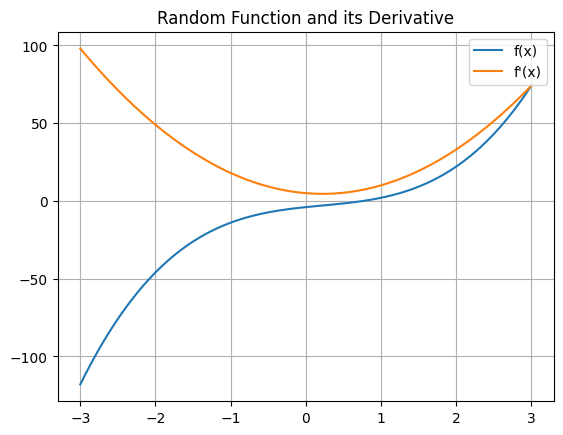

In [68]:
# ==================== START OF CODE SOLUTION ====================
def f(x):
    return 3*x**3 - 2*x**2 + 5*x - 4

def f_prime(x):
    return 9*x**2 - 4*x + 5

x = torch.linspace(-3, 3, 100)

plt.plot(x, f(x), label='f(x)')
plt.plot(x, f_prime(x), label="f'(x)")
plt.legend()
plt.title('Random Function and its Derivative')
plt.grid(True)
plt.show()
# ===================== END OF CODE SOLUTION =====================


## Sigmoid Function
The sigmoid function is defined as:
$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

**Exercise 1:** Calculate its derivative and express it in terms of $\sigma(x)$

**Your Solution:**



Given the sigmoid:
$$
\sigma(x) = \frac{1}{1 + e^{-x}} = (1 + e^{-x})^{-1}
$$

we compute its derivative $\sigma'(x)$.

$$
\sigma(x) = (1 + e^{-x})^{-1}
$$

Let $g(u) = u^{-1}$ and $u(x) = 1 + e^{-x}$ (We are applying the chain rule)

$$
\sigma(x) = g(u(x))
$$
Then:

$$
\frac{d}{dx}\sigma(x) = g'(u(x)) \cdot u'(x)

$$

We have $g'(u) = -u^{-2}$ and $u'(x) = \frac{d}{dx}(1 + e^{-x}) = -e^{-x}$.  

Therefore:

$$
\sigma'(x) = - (1 + e^{-x})^{-2} \cdot (-e^{-x}) = \frac{e^{-x}}{(1 + e^{-x})^{2}}
$$

Write the result as a product:

$$
\sigma'(x) = \frac{1}{1 + e^{-x}} \cdot \frac{e^{-x}}{1 + e^{-x}}
$$

Recognize the first factor as $\sigma(x)$.  

For the second factor, observe:

$$
\frac{e^{-x}}{1 + e^{-x}} = \frac{1 + e^{-x} - 1}{1 + e^{-x}} = 1 - \frac{1}{1 + e^{-x}} = 1 - \sigma(x)
$$

$$
\boxed{\sigma'(x) = \sigma(x)\,\bigl(1 - \sigma(x)\bigr)}
$$

**Exercise 1:** Implement the sigmoid function and its derivative, then visualize both.

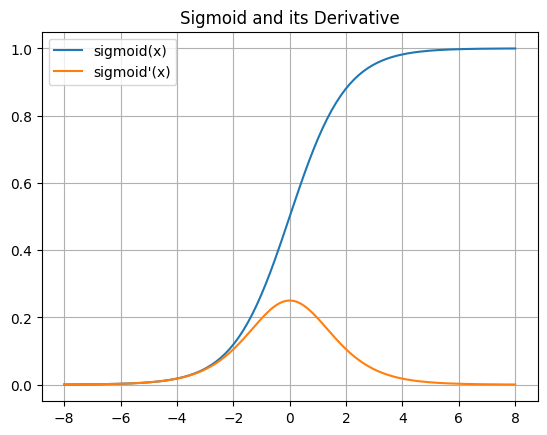

In [69]:
# ==================== START OF CODE SOLUTION ====================
def sigmoid(x):
    return 1 / (1 + torch.exp(-x))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

x = torch.linspace(-8, 8, 200)
plt.plot(x, sigmoid(x), label='sigmoid(x)')
plt.plot(x, sigmoid_derivative(x), label="sigmoid'(x)")
plt.title('Sigmoid and its Derivative')
plt.legend(); plt.grid(True); plt.show()
# ===================== END OF CODE SOLUTION =====================


## 4. ReLU Function
The Rectified Linear Unit (ReLU) is defined as:
$$
f(x) = \max(0, x)
$$

**Exercise 1:** Calculate the derivative of ReLU.

**Your Solution**


Given the Rectified Linear Unit (ReLU) function:

$$
\text{ReLU}(x) = \max(0, x)
$$

we compute its derivative $\text{ReLU}'(x)$.



The ReLU function can be written as a piecewise function:

$$
\text{ReLU}(x) =
\begin{cases}
x, & \text{if } x > 0, \\
0, & \text{if } x \leq 0.
\end{cases}
$$



For $x > 0$:

$$
\frac{d}{dx}\text{ReLU}(x) = \frac{d}{dx}(x) = 1
$$

For $x < 0$:

$$
\frac{d}{dx}\text{ReLU}(x) = \frac{d}{dx}(0) = 0
$$

At $x = 0$, the derivative is undefined because of the discontinuity in slope (the function is continuous but not differentiable at 0).  
In practice, deep learning frameworks define it as either 0 or 1 at $x = 0$ for convenience, most commonly **0**.

$$
\boxed{
\text{ReLU}'(x) =
\begin{cases}
1 & \text{if } x > 0, \\
0 & \text{if } x \leq 0.
\end{cases}
}
$$


**Exercise 2:** Implement ReLU and its derivative, then visualize both.

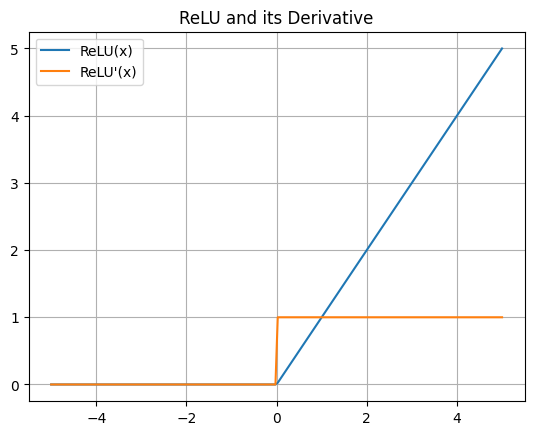

In [70]:
# ==================== START OF CODE SOLUTION ====================
def relu(x):
    return torch.maximum(torch.tensor(0.0), x)

def relu_derivative(x):
    return (x > 0).float()

x = torch.linspace(-5, 5, 200)
plt.plot(x, relu(x), label='ReLU(x)')
plt.plot(x, relu_derivative(x), label="ReLU'(x)")
plt.title('ReLU and its Derivative')
plt.legend(); plt.grid(True); plt.show()
# ===================== END OF CODE SOLUTION =====================


## Binary Cross-Entropy Loss
For a single prediction $y_{pred}$ and true label $y \in \{0, 1\}$, the **binary cross-entropy loss** is:
$$
\mathcal{L} = -[y \log(y_{pred}) + (1 - y) \log(1 - y_{pred})]
$$


**Exercise 1: calculate the derivative with respect to $y_{pred}$**

**Your Solution:**

We derive the gradient of the **binary cross-entropy loss** with respect to the model output (logit).  
This is the most fundamental form used in binary classification neural networks.


Let the model output (before activation) be $z$, and the **sigmoid function** be

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The predicted probability is:

$$
\hat{y} = \sigma(z)
$$

and the true label is $y \in \{0, 1\}$.

The **binary cross-entropy loss** is defined as:

$$
L(y, \hat{y}) = - \big( y \log(\hat{y}) + (1 - y)\log(1 - \hat{y}) \big)
$$


Differentiate $L$ with respect to $\hat{y}$:

$$
\frac{\partial L}{\partial \hat{y}}
= - \left( \frac{y}{\hat{y}} - \frac{1 - y}{1 - \hat{y}} \right)
$$

Simplify:

$$
\frac{\partial L}{\partial \hat{y}}
= \frac{\hat{y} - y}{\hat{y}(1 - \hat{y})}
$$

Since $\hat{y} = \sigma(z)$, and

$$
\sigma'(z) = \sigma(z)\,(1 - \sigma(z)) = \hat{y}(1 - \hat{y}),
$$

we have:

$$
\frac{\partial \hat{y}}{\partial z} = \hat{y}(1 - \hat{y})
$$

We want $\Large{\frac{\partial L}{\partial z}}$:

$$
\frac{\partial L}{\partial z}
= \frac{\partial L}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z}
$$

Substitute both expressions:

$$
\frac{\partial L}{\partial z}
= \left( \frac{\hat{y} - y}{\hat{y}(1 - \hat{y})} \right) \cdot \hat{y}(1 - \hat{y})
$$

Simplify:

$$
\frac{\partial L}{\partial z} = \hat{y} - y
$$

The derivative of the **binary cross-entropy loss** with respect to the model logit $z$ is:

$$
\boxed{\frac{\partial L}{\partial z} = \sigma(z) - y}
$$

**Exercise 2:** Implement *BCE* and its derivative, then visualize both.

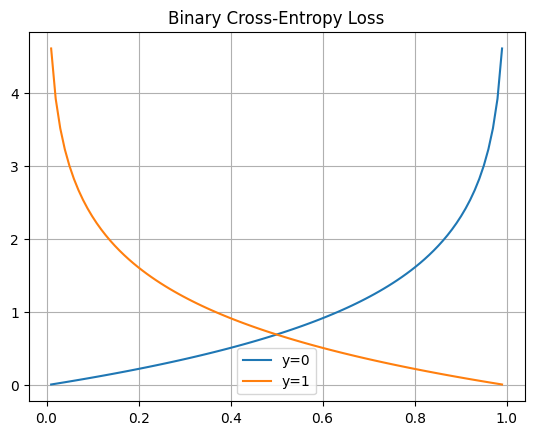

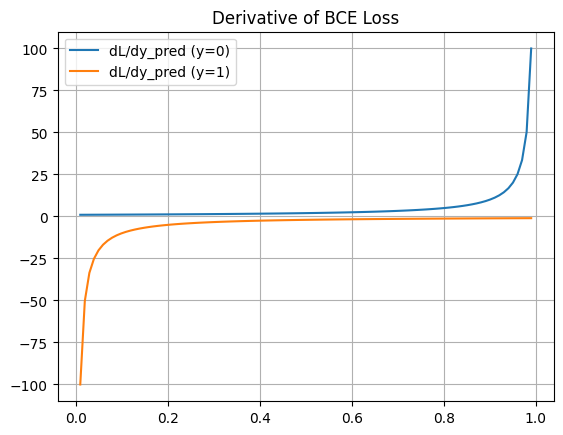

In [71]:
# ==================== START OF CODE SOLUTION ====================
def binary_cross_entropy(y_pred, y):
    eps = 1e-8
    return - (y * torch.log(y_pred + eps) + (1 - y) * torch.log(1 - y_pred + eps))

def bce_derivative(y_pred, y):
    eps = 1e-8
    return - (y / (y_pred + eps)) + ((1 - y) / (1 - y_pred + eps))

y_pred = torch.linspace(0.01, 0.99, 100)

for label in [0, 1]:
    plt.plot(y_pred, binary_cross_entropy(y_pred, torch.tensor(label)), label=f'y={label}')
plt.title('Binary Cross-Entropy Loss')
plt.legend(); plt.grid(True); plt.show()

for label in [0, 1]:
    plt.plot(y_pred, bce_derivative(y_pred, torch.tensor(label)), label=f"dL/dy_pred (y={label})")
plt.title('Derivative of BCE Loss')
plt.legend(); plt.grid(True); plt.show()
# ===================== END OF CODE SOLUTION =====================
